# Result Generation

Retrieval and reranking end with a short list of passages. This notebook runs the three forms
of the book section *Result Generation* that turn such a list into an answer: a **reader** that
marks the answer span inside a passage, a **generator** that writes a new answer from the
passages, and a **synthesizer** that retrieves several times before it writes. We close with
**citations**: each answer comes back with the passages it relied on, and we check that the
quoted evidence is really there.

**Learning goals:**
- Run a BERT reader and see how it scores the start and end of the answer span
- See what a reader cannot do: combine passages, notice the wrong year, or say "I don't know"
- Generate a grounded answer with the book's prompt skeleton and compare it with the reader
- Build a hard-wired multi-hop synthesizer and compare it with a single retrieval pass
- Return structured citations and verify every quote against its passage

**Prerequisites:** ch07-02 (the RAG pipeline and the `nobel-2025` knowledge base), Chapter 5 (BERT, cross-encoders)

## Setup

In [1]:
import os
import json
import re
import time

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"

import logging
import warnings
warnings.filterwarnings("ignore")
logging.getLogger("sentence_transformers").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import torch
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer, AutoModelForQuestionAnswering
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

from shared.display import print_table, display_md
from shared.collections import load_collection
from ch07_chunking import contains
from ch07_rag import (
    build_units, label, SparseIndex, DenseIndex, retrieve, read_span,
    format_passages, build_prompt, ask, CACHED,
)

<div style="border-left: 4px solid #64748B; background: rgba(100, 116, 139, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#64748B; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Models and AWS</strong><br>
The first run downloads three models from Hugging Face (about 450 MB in total): all-MiniLM-L6-v2 and the ms-marco-MiniLM cross-encoder from ch07-02, and the reader distilbert-base-uncased-distilled-squad (about 260 MB). The generator and the synthesizer call Claude on AWS Bedrock. Without AWS credentials, those cells show answers recorded earlier, marked as such.
</div>

We rebuild the retrieval chain of ch07-02 in one cell: parents and children, BM25 over the
parents, dense embeddings over the children, reciprocal rank fusion, and the cross-encoder.
`search(question, k)` returns the top $k$ parents after reranking.

In [2]:
collection = load_collection("nobel-2025")
parents, children = build_units(collection, parent_size=2000, child_size=400)

bi_encoder = SentenceTransformer("all-MiniLM-L6-v2")
cross_encoder = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")
sparse = SparseIndex(parents)
dense = DenseIndex(children, bi_encoder)

def search(question, k=5):
    """Top-k parents for a question: hybrid retrieval, then cross-encoder reranking."""
    return [p for p, _ in retrieve(question, sparse, dense, children, parents,
                                   cross_encoder, top_k=k)]

display_md(f"Index ready: **{len(parents)} parents**, **{len(children)} children**.")

Index ready: **634 parents**, **2682 children**.

We follow the book's running question. The model already knows the 2025 prize from training
(ch07-02 showed this), so here the point is not *whether* it can answer, but *where the answer
comes from*: the passages, and nothing else.

In [3]:
QUESTION = "Who won the Nobel Prize in Physics in 2025?"
timing = {}

## The Reader

A reader does not write. It reads the question and a passage together and predicts where in
the passage the answer starts and where it ends. We run the book's code unchanged: the model
is DistilBERT fine-tuned on SQuAD, and the passage is the book's one-sentence context.

In [4]:
name = "distilbert-base-uncased-distilled-squad"
tokenizer = AutoTokenizer.from_pretrained(name)
model = AutoModelForQuestionAnswering.from_pretrained(name)

context = (
    "John Clarke, Michel Devoret, and John Martinis won the 2025 Nobel "
    "Prize in Physics for their discovery of macroscopic quantum tunnelling."
)

enc = tokenizer(QUESTION, context, return_offsets_mapping=True, return_tensors="pt")
offsets = enc.pop("offset_mapping")[0]
with torch.no_grad():
    output = model(**enc)

start = output.start_logits.argmax()   # highest-scoring start token
end = output.end_logits.argmax()       # highest-scoring end token
answer = context[offsets[start][0]: offsets[end][1]]
display_md(f"**Span:** {answer}")

**Span:** John Clarke, Michel Devoret, and John Martinis

The span is exactly the book's answer. The two scores behind it show how the reader decides.
Every passage token gets a start score and an end score; the answer runs from the highest start
to the highest end.

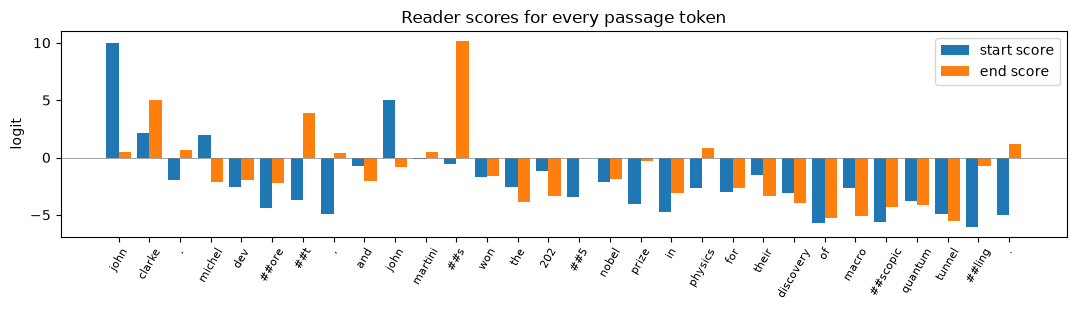

In [5]:
tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
in_passage = [s == 1 for s in enc.sequence_ids(0)]
idx = [i for i, keep in enumerate(in_passage) if keep]

fig, ax = plt.subplots(figsize=(11, 3.2))
x = range(len(idx))
ax.bar([i - 0.2 for i in x], output.start_logits[0][idx], width=0.4, label="start score")
ax.bar([i + 0.2 for i in x], output.end_logits[0][idx], width=0.4, label="end score")
ax.set_xticks(list(x), [tokens[i] for i in idx], rotation=60, fontsize=8)
ax.axhline(0, color="gray", lw=0.5)
ax.set_ylabel("logit")
ax.set_title("Reader scores for every passage token")
ax.legend()
plt.tight_layout()
plt.show()

The start score peaks on "john" at the very beginning, the end score on "martinis". Everything
between them is the answer, copied character by character from the passage.

### Reading the retrieved passages

In the pipeline the reader gets the reranked passages, not a sentence written for it. A
passage can be longer than the model's 384-token window, so `read_span` reads it in overlapping
windows and keeps the best span (start plus end score). We read each of the top 5 passages and
pick the span with the highest score.

In [6]:
def read(question, ids):
    """Best span per passage, sorted by reader score."""
    spans = [dict(read_span(question, parents[p]["body"], tokenizer, model), passage=p)
             for p in ids]
    return sorted(spans, key=lambda s: -s["score"])

ids = search(QUESTION)
t0 = time.perf_counter()
spans = read(QUESTION, ids)
timing["Reader"] = time.perf_counter() - t0

print_table([[label(parents[s["passage"]]), s["answer"], f"{s['score']:.1f}"] for s in spans],
            ["Passage", "Span", "Reader score"])

| Passage                                         | Span             |   Reader score |
|:------------------------------------------------|:-----------------|---------------:|
| John Clarke (physicist) > Introduction          | John Clarke      |           18.9 |
| 2025 Nobel Prizes > Prizes                      | John M. Martinis |           14.5 |
| List of Nobel laureates in Physics > Laureates  | John Clarke      |           10.3 |
| List of Nobel laureates in Physics > Statistics | Max von Laue     |           10   |
| 2025 Nobel Prizes > Introduction                | Nobel Foundation |            6.6 |

The reader's best answer is "John Clarke", one name out of three. The passages state the
laureates in different shapes: an introduction that names Clarke first, a prize table with one
laureate per row. Each span is one stretch of one passage, so no single span can hold all three
names. This is the reader's ceiling: it can point, but it cannot combine.

### What a reader cannot do

Two more questions show the other limits. The first is the book's generator question about the
2025 prize. The second asks about a year that the knowledge base does not cover.

In [7]:
reader_questions = [
    "What contributions led to the 2025 Nobel Prize in Physics?",
    "Who won the Nobel Prize in Physics in 2027?",
]
rows = []
for q in reader_questions:
    best = read(q, search(q))[0]
    rows.append([q, best["answer"], label(parents[best["passage"]])])
print_table(rows, ["Question", "Best span", "From passage"])

| Question                                                   | Best span                                                                                                                     | From passage               |
|:-----------------------------------------------------------|:------------------------------------------------------------------------------------------------------------------------------|:---------------------------|
| What contributions led to the 2025 Nobel Prize in Physics? | decisive contributions to the IceCube Neutrino Observatory and the discovery of high-energy neutrinos of astrophysical origin | 2026 Nobel Prizes > Prizes |
| Who won the Nobel Prize in Physics in 2027?                | John M. Martinis                                                                                                              | 2025 Nobel Prizes > Prizes |

- **The wrong year, faithfully copied.** Retrieval ranks a passage about the *2026* prize near
  the top, because it is about physics Nobel contributions and only the year differs. The
  reader copies a span from whichever passage scores best, and it does not check that the
  passage answers the question it was asked.
- **No "I don't know".** For 2027 there is no answer anywhere in the collection, yet the reader
  returns a name. This SQuAD model always marks some span; it has no way to abstain.

A reader is faithful to its passage, never to the question. Whether its answer is right
depends entirely on retrieval putting the right passage in front of it.

## The Generator

A generator gets the same passages, but writes the answer. We use the book's grounded-answer
prompt skeleton from ch07-02: task and scope, the numbered passages, the question, and a
closing reminder to base every claim on the passages and to say "I don't know" otherwise.

In [8]:
def generate(question, key, k=5, fmt="one short paragraph"):
    """Grounded answer from the top-k passages; returns (answer, live, seconds)."""
    prompt = build_prompt(question, search(question, k), parents, format=fmt)
    t0 = time.perf_counter()
    answer, live = ask(prompt, CACHED[key], max_tokens=600)
    return answer.strip(), live, time.perf_counter() - t0

rows = []
for q, key in [(QUESTION, "gen-2025"),
               (reader_questions[0], "gen-contributions"),
               (reader_questions[1], "gen-2027")]:
    answer, live, seconds = generate(q, key)
    if q == QUESTION:
        timing["Generator"] = seconds if live else None
    rows.append([q, answer + ("" if live else " *(cached)*")])
print_table(rows, ["Question", "Generated answer"])

| Question                                                   | Generated answer                                                                                                                                                                                                                                                                                                                                                                                                                                             |
|:-----------------------------------------------------------|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Who won the Nobel Prize in Physics in 2025?                | John Clarke, Michel Devoret, and John M. Martinis won the 2025 Nobel Prize in Physics. They were honored "for the discovery of macroscopic quantum mechanical tunnelling and energy quantisation in an electric circuit" [1][4]. Passage [5] adds that the three worked together in the 1980s under Clarke's leadership, and that their work on macroscopic quantum phenomena using the Josephson effect earned them the prize [5].                          |
| What contributions led to the 2025 Nobel Prize in Physics? | The 2025 Nobel Prize in Physics was awarded to John Clarke, Michel Devoret, and John M. Martinis "for the discovery of macroscopic quantum mechanical tunnelling and energy quantisation in an electric circuit" [2][5]. The passages give only this prize citation. They do not describe the experiments or findings in more detail.                                                                                                                        |
| Who won the Nobel Prize in Physics in 2027?                | I don't know who won the Nobel Prize in Physics in 2027. The passages don't cover that year. The most recent laureate listed is for 2026, Francis Halzen, cited "for decisive contributions to the IceCube Neutrino Observatory and the discovery of high-energy neutrinos of astrophysical origin" [2]. The count of 230 laureates is also given "as of 2026" [1][4]. For 2025, the prize went to John Clarke, Michel Devoret, and John M. Martinis [2][3]. |

The same passages, three different outcomes from the reader's:

- **It combines.** All three laureates appear in one sentence, merged from several passages,
  each claim marked with the passage it came from.
- **It reads the question.** The 2026 passage is in its context too, but the answer names the
  2025 prize, and says plainly that the passages give only the prize citation and no further
  detail.
- **It abstains.** For 2027 the answer says the passages do not cover that year, instead of
  inventing a name.

This freedom is also the risk the book warns about: a generator writes equally fluent text
whether or not the facts are in its context. The citation check at the end of this notebook is
the safeguard.

## The Synthesizer

Some questions need evidence that no single retrieval brings back, because the query does not
contain the words that lead to it:

In [9]:
DEEP_QUESTION = "Where do the 2025 Nobel laureates in physics work today?"

The answer lives in each laureate's own article, but the question names no laureate. A
synthesizer therefore retrieves in hops. The plan is fixed in code; only the queries change
with what the previous hop found:

1. **Laureates.** Retrieve 3 passages for the prize and let the model extract the names.
2. **Careers.** Retrieve 2 passages for "*name* career" for each laureate.

In [10]:
t0 = time.perf_counter()
hops = [("1 laureates", QUESTION, search(QUESTION, k=3))]

extract_prompt = (
    "List the people who won the 2025 Nobel Prize in Physics according to the passages "
    "below. Reply with a JSON list of full names only.\n\n"
    f"<passages>\n{format_passages(hops[0][2], parents)}\n</passages>"
)
reply, live = ask(extract_prompt, CACHED["synth-names"], max_tokens=200)
names = json.loads(re.search(r"\[.*\]", reply, re.S).group(0))

for n in names:
    hops.append(("2 careers", f"{n} career", search(f"{n} career", k=2)))

evidence = list(dict.fromkeys(p for _, _, ids in hops for p in ids))   # keep order, drop repeats

print_table([[hop, q, "; ".join(label(parents[p]) for p in ids)] for hop, q, ids in hops],
            ["Hop", "Query", "Top passages"])
display_md(f"**Names from hop 1:** {', '.join(names)}. "
           f"**{len(evidence)} distinct passages** collected over {len(hops)} retrievals.")

| Hop         | Query                                       | Top passages                                                                                                                      |
|:------------|:--------------------------------------------|:----------------------------------------------------------------------------------------------------------------------------------|
| 1 laureates | Who won the Nobel Prize in Physics in 2025? | List of Nobel laureates in Physics > Laureates; List of Nobel laureates in Physics > Statistics; 2025 Nobel Prizes > Introduction |
| 2 careers   | John Clarke career                          | John Clarke (physicist) > Education and career; John Clarke (physicist) > Introduction                                            |
| 2 careers   | Michel Devoret career                       | Michel Devoret > Career; Michel Devoret > Introduction                                                                            |
| 2 careers   | John M. Martinis career                     | John M. Martinis > Career; John M. Martinis > Introduction                                                                        |

**Names from hop 1:** John Clarke, Michel Devoret, John M. Martinis. **9 distinct passages** collected over 4 retrievals.

Hop 1 turns the question into names; hop 2 turns each name into that person's own career
sections. The final step is a generator over all collected passages. We also ask for the output
format of the next section: an answer plus a list of citations, each with a quote copied from
its passage.

In [11]:
CITATION_FORMAT = (
    'Reply with JSON only: {"answer": "...", "citations": '
    '[{"id": 1, "quote": "exact words copied from passage 1"}]}. '
    "Every quote must be copied verbatim from the cited passage."
)

synth_prompt = build_prompt(DEEP_QUESTION, evidence, parents,
                            format="one short paragraph per laureate") + "\n\n" + CITATION_FORMAT
reply, live = ask(synth_prompt, CACHED["synth-answer"], max_tokens=1500)
synth = json.loads(re.search(r"\{.*\}", reply, re.S).group(0))
synth_seconds = time.perf_counter() - t0
if live:
    timing["Synthesizer"] = synth_seconds

display_md(f"**Answer{'' if live else ' (cached)'}:**\n\n{synth['answer']}")

**Answer:**

John Clarke: He is a Professor Emeritus at the University of California, Berkeley [5]. He joined Lawrence Berkeley National Laboratory in 1969 and retired from it in 2010 as a faculty senior scientist [4]. The passages give no current workplace beyond this emeritus status.

Michel Devoret: He is Professor of Physics at the University of California, Santa Barbara, and Professor Emeritus of Applied Physics at Yale University. He also serves as Chief Scientist for Quantum Hardware at Google Quantum AI [7].

John M. Martinis: He is Professor of Physics at the University of California, Santa Barbara [9]. In 2020 he joined Silicon Quantum Computing, a start-up founded in Australia [8]. In 2026 he was appointed to the President's Council of Advisors on Science and Technology (PCAST) [8]. The passages do not say whether he is still at Silicon Quantum Computing.

For a fair baseline, a single retrieval pass gets **the same number of passages** and the same
prompt. If it loses, it loses for lack of hops, not for lack of context.

In [12]:
single_ids = search(DEEP_QUESTION, k=len(evidence))
single_answer, live = ask(build_prompt(DEEP_QUESTION, single_ids, parents,
                                       format="one short paragraph per laureate"),
                          CACHED["single-pass"], max_tokens=1500)

display_md(
    f"**{len(single_ids)} passages:** " + "; ".join(label(parents[p]) for p in single_ids) + "\n\n"
    f"**Answer{'' if live else ' (cached)'}:**\n\n{single_answer.strip()}"
)

**9 passages:** List of Nobel laureates in Physics > Laureates; List of Nobel laureates in Physics > Statistics; List of Nobel laureates in Physics > Statistics; List of Nobel laureates in Physics > Laureates; List of Nobel laureates in Physics > Number of Nobel laureates in Physics by country; John M. Martinis > Introduction; University of California, Santa Barbara > Notable faculty; List of Nobel laureates in Physics > Laureates; Fred Ramsdell > Introduction

**Answer:**

**John Clarke:** The passages don't say where he works, so I don't know. They only list him as a 2025 laureate, with the United Kingdom as his country, for the discovery of macroscopic quantum mechanical tunnelling and energy quantisation in an electric circuit [1].

**Michel Devoret:** Passage [7] lists him as a 2025 Nobel laureate among "current and past" University of California, Santa Barbara faculty. It doesn't say whether he is current or past faculty, so I can only say he has a UCSB affiliation. His country is listed as the United States [1].

**John M. Martinis:** He is described as a Professor of Physics at the University of California, Santa Barbara [6]. Passage [7] also lists him among UCSB's Nobel laureate faculty. Passage [6] says he led a team at the Quantum AI Lab that developed a superconducting quantum computer, but it uses the past tense, so it doesn't establish that he works there now.

The query's words are "2025", "Nobel laureates", "physics": retrieval answers with laureate
lists and statistics, pages about the prize rather than about the people. Which institutions
reach each approach, first in its passages, then in its answer?

In [13]:
INSTITUTIONS = ["Berkeley", "Yale", "Santa Barbara", "Saclay", "Google"]

def mentions(texts, fact):
    return "yes" if any(contains(t, fact) for t in texts) else "-"

single_texts = [parents[p]["body"] for p in single_ids]
synth_texts = [parents[p]["body"] for p in evidence]
print_table([[f, mentions(single_texts, f), mentions([single_answer], f),
              mentions(synth_texts, f), mentions([synth["answer"]], f)] for f in INSTITUTIONS],
            ["Institution", "Single: passages", "Single: answer",
             "Synthesizer: passages", "Synthesizer: answer"])

| Institution   | Single: passages   | Single: answer   | Synthesizer: passages   | Synthesizer: answer   |
|:--------------|:-------------------|:-----------------|:------------------------|:----------------------|
| Berkeley      | -                  | -                | yes                     | yes                   |
| Yale          | -                  | -                | yes                     | yes                   |
| Santa Barbara | yes                | yes              | yes                     | yes                   |
| Saclay        | -                  | -                | yes                     | -                     |
| Google        | -                  | -                | yes                     | yes                   |

With the same budget, the single pass reaches almost none of the laureates' institutions, and
no prompt can make its answer name what its passages do not hold. The synthesizer's second hop
lands on each laureate's career section, which is where the universities are. Retrieving more
passages for the original question does not close the gap: the extra passages are more prize
pages. The price is two model calls and four retrievals instead of one of each.

The book's own example, "what teams and organizations were behind the 2025 Nobel-winning
quantum computing research?", is a milder case: "quantum computing" already points at Martinis
and Clarke, so a single pass with enough passages reaches most of their sections. Hops pay off
when the question does not name what the answer is about.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">One retrieval pass answers what one query can reach</strong><br>
The single pass found what the question's words point at: the prize. The synthesizer found what the <em>answer</em> points at: the laureates' names became new queries, and those queries reached the passages that hold their institutions. That is the multi-hop loop, here with a fixed plan; the next notebook lets an agent decide the hops itself.
</div>

## Citations

Every citation should let a reader check the claim. The synthesizer returned passage numbers
and quotes; we expand each into the book's citation record, with the passage identifier, its
source, the URL of the exact Wikipedia revision, and the original text.

In [14]:
def citation_record(c):
    p = evidence[c["id"] - 1]                     # passage numbers in the prompt start at 1
    return {"passage_id": p, "source": label(parents[p]),
            "url": parents[p]["url"], "original_text": c["quote"]}

records = [citation_record(c) for c in synth["citations"]]
display_md(f"```json\n{json.dumps(records[0], indent=2, ensure_ascii=False)}\n```")

```json
{
  "passage_id": 28,
  "source": "John Clarke (physicist) > Introduction",
  "url": "https://en.wikipedia.org/w/index.php?oldid=1380998955",
  "original_text": "a British experimental physicist and Professor Emeritus at the University of California, Berkeley"
}
```

A record is only useful if it is true. The check is simple: does the quoted text actually occur
in the cited passage? We compare case- and whitespace-insensitively.

In [15]:
def verify(records):
    return [[r["passage_id"], r["source"], r["original_text"][:70],
             "yes" if contains(parents[r["passage_id"]]["body"], r["original_text"]) else "**NO**"]
            for r in records]

rows = verify(records)
print_table(rows, ["Passage", "Source", "Quote", "In passage?"])
display_md(f"**{sum(r[3] == 'yes' for r in rows)} of {len(rows)}** quotes found verbatim "
           "in their cited passage.")

|   Passage | Source                                         | Quote                                                                  | In passage?   |
|----------:|:-----------------------------------------------|:-----------------------------------------------------------------------|:--------------|
|        28 | John Clarke (physicist) > Introduction         | a British experimental physicist and Professor Emeritus at the Univers | yes           |
|        29 | John Clarke (physicist) > Education and career | eventually retiring as a faculty senior scientist in the Materials Sci | yes           |
|        35 | Michel Devoret > Introduction                  | He is Professor of Physics at the University of California, Santa Barb | yes           |
|        35 | Michel Devoret > Introduction                  | He serves as the Chief Scientist for Quantum Hardware at Google Quantu | yes           |
|        41 | John M. Martinis > Introduction                | Professor of Physics at the University of California, Santa Barbara    | yes           |
|        43 | John M. Martinis > Career                      | In 2020, Martinis joined Silicon Quantum Computing, a start-up founded | yes           |
|        43 | John M. Martinis > Career                      | In 2026, he was appointed to the President's Council of Advisors on Sc | yes           |

**7 of 7** quotes found verbatim in their cited passage.

A current model usually copies its quotes faithfully, as here. To see what the check catches, we
simulate a common slip: the model cites the neighbouring passage. We shift every citation number by one.

In [16]:
shifted = [citation_record({**c, "id": c["id"] % len(evidence) + 1}) for c in synth["citations"]]
rows = verify(shifted)
print_table(rows, ["Passage", "Source", "Quote", "In passage?"])
display_md(f"**{sum(r[3] == 'yes' for r in rows)} of {len(rows)}** quotes found after the shift.")

|   Passage | Source                                         | Quote                                                                  | In passage?   |
|----------:|:-----------------------------------------------|:-----------------------------------------------------------------------|:--------------|
|        37 | Michel Devoret > Career                        | a British experimental physicist and Professor Emeritus at the Univers | **NO**        |
|        28 | John Clarke (physicist) > Introduction         | eventually retiring as a faculty senior scientist in the Materials Sci | **NO**        |
|        43 | John M. Martinis > Career                      | He is Professor of Physics at the University of California, Santa Barb | **NO**        |
|        43 | John M. Martinis > Career                      | He serves as the Chief Scientist for Quantum Hardware at Google Quantu | **NO**        |
|        26 | List of Nobel laureates in Physics > Laureates | Professor of Physics at the University of California, Santa Barbara    | **NO**        |
|        41 | John M. Martinis > Introduction                | In 2020, Martinis joined Silicon Quantum Computing, a start-up founded | **NO**        |
|        41 | John M. Martinis > Introduction                | In 2026, he was appointed to the President's Council of Advisors on Sc | **NO**        |

**0 of 7** quotes found after the shift.

A wrong citation looks exactly as convincing as a right one until someone follows the link.
A quote check is cheap, needs no model, and catches it. It does not prove that the claim
follows from the quote, only that the evidence exists where the answer says it does; judging
whether it supports the claim is the faithfulness measure of *Evaluating RAG*.

## Choosing Among the Three

The book chooses by question, context, intent, and risk. This run adds the cost side, measured
on the questions above. The seconds count reading or generating after retrieval; for the
synthesizer they include its four retrievals, since those are part of its answer.

In [17]:
seconds = lambda form: f"{timing[form]:.1f}" if timing.get(form) else "cached"
print_table([
    ["Reader", "DistilBERT (66M parameters), local", "0", seconds("Reader"),
     "one verbatim span per passage"],
    ["Generator", "Claude on Bedrock", "1", seconds("Generator"),
     "combined answer with citations, or \"I don't know\""],
    ["Synthesizer", "Claude on Bedrock", "2", seconds("Synthesizer"),
     "answer built over two hops, quotes per claim"],
], ["Form", "Model", "LLM calls", "Seconds", "Returns"])

| Form        | Model                              |   LLM calls |   Seconds | Returns                                           |
|:------------|:-----------------------------------|------------:|----------:|:--------------------------------------------------|
| Reader      | DistilBERT (66M parameters), local |           0 |       0.2 | one verbatim span per passage                     |
| Generator   | Claude on Bedrock                  |           1 |       3.7 | combined answer with citations, or "I don't know" |
| Synthesizer | Claude on Bedrock                  |           2 |      10.8 | answer built over two hops, quotes per claim      |

The reader is local, cheap, and cannot add a word its source did not say, which suits exact
quotes and high-risk domains. The generator is the default for a question with a direct answer.
The synthesizer pays several round trips for questions whose evidence is spread across documents.

## Summary

| Form | What it does | Strength | Limit seen here |
|---|---|---|---|
| Reader | marks the answer span in a passage | verbatim, local, fast | one name of three; copies the wrong year; never abstains |
| Generator | writes the answer from the passages | combines, reads the question, abstains | fluent even when wrong, so it needs citations |
| Synthesizer | retrieves in several hops, then generates | reaches evidence the question never named | more calls and more time |
| Citations | answer plus quote per claim | checkable without a model | a quote shows the evidence exists, not that it supports the claim |

Retrieval finds the passages; result generation decides what the user gets back. A reader
points at the answer, a generator states it, a synthesizer goes looking for the rest, and
citations let anyone check all three.

## Try it yourself

1. Ask the reader "Which university did Michel Devoret join in 2002?" Does the top passage hold
   the answer, and does the reader find it?
2. Remove the grounding sentence ("If the answer is not in them, say you don't know") from
   `PROMPT` in <a href="ch07_rag.py">ch07_rag.py</a> and ask the generator about 2027 again.
   Does the answer change?
3. Run the synthesizer on the book's question, "What teams and organizations were behind the
   2025 Nobel-winning quantum computing research?", and compare it with a single pass of the
   same size. Why is the gap smaller?